In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA842423/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,Organism,Platform,ReleaseDate,create_date,version,samp_collect_device,samp_mat_process,Sample.Name,source_material_id,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
1,SRR19409932,AMPLICON,602,56200312,PRJNA842423,SAMN28664627,Metagenome or environmental,35385707,UNIVERSIDAD NACIONAL AUTONOMA DE MEXICO,2017-07-31,⋯,oral metagenome,ILLUMINA,2022-11-25T00:00:00Z,2022-05-25T17:38:00Z,1,sterile eppendorf container,QIAamp DNA mini kit,10S,10S,SRP377112
2,SRR19409933,AMPLICON,602,54386486,PRJNA842423,SAMN28664626,Metagenome or environmental,35039616,UNIVERSIDAD NACIONAL AUTONOMA DE MEXICO,2016-04-26,⋯,oral metagenome,ILLUMINA,2022-11-25T00:00:00Z,2022-05-25T17:39:00Z,1,sterile eppendorf container,QIAamp DNA mini kit,9S,9S,SRP377112
3,SRR19409934,AMPLICON,602,57456084,PRJNA842423,SAMN28664625,Metagenome or environmental,36522573,UNIVERSIDAD NACIONAL AUTONOMA DE MEXICO,2016-04-26,⋯,oral metagenome,ILLUMINA,2022-11-25T00:00:00Z,2022-05-25T17:39:00Z,1,sterile eppendorf container,QIAamp DNA mini kit,8S,8S,SRP377112
4,SRR19409935,AMPLICON,602,52863426,PRJNA842423,SAMN28664624,Metagenome or environmental,33364354,UNIVERSIDAD NACIONAL AUTONOMA DE MEXICO,2016-04-26,⋯,oral metagenome,ILLUMINA,2022-11-25T00:00:00Z,2022-05-25T17:38:00Z,1,sterile eppendorf container,QIAamp DNA mini kit,7S,7S,SRP377112
5,SRR19409936,AMPLICON,602,51148930,PRJNA842423,SAMN28664623,Metagenome or environmental,32504330,UNIVERSIDAD NACIONAL AUTONOMA DE MEXICO,2016-04-26,⋯,oral metagenome,ILLUMINA,2022-11-25T00:00:00Z,2022-05-25T17:38:00Z,1,sterile eppendorf container,QIAamp DNA mini kit,6S,6S,SRP377112
6,SRR19409937,AMPLICON,602,42574644,PRJNA842423,SAMN28664622,Metagenome or environmental,27215718,UNIVERSIDAD NACIONAL AUTONOMA DE MEXICO,2016-04-26,⋯,oral metagenome,ILLUMINA,2022-11-25T00:00:00Z,2022-05-25T17:39:00Z,1,sterile eppendorf container,QIAamp DNA mini kit,5S,5S,SRP377112


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "HOST"                           "Instrument"                    
[21] "isolation_source"               "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Organism"                       "Platform"                      
[29] "ReleaseDate"                    "create_date"                   
[31] "version"                        "samp_collect_device"           
[33] "samp_mat_process"               "Sample.Name"                   
[35] "source_material_id"             "SRA.Study"

In [7]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$isolation_source,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC',
    title = "Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [8]:
# 根据样本名称设置状态
for (i in 1:nrow(uniform_meta)) {
    sample_name <- uniform_meta$sample_name[i]
    
    if (grepl("S", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- " non-carious"
    } else if (grepl("C", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "carious"
    }
    # 如果不匹配任何模式，保持为NA
}

In [9]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 27
[1] 27


In [10]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,PRJNA842423,SRR19409932,10S,NA,NA,NA,V3-V4,ILLUMINA,Mexico,dental plaque,2022-11-25T00:00:00Z,F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC,Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals,YES,non-carious,NO
2,PRJNA842423,SRR19409933,9S,NA,NA,NA,V3-V4,ILLUMINA,Mexico,dental plaque,2022-11-25T00:00:00Z,F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC,Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals,YES,non-carious,NO
3,PRJNA842423,SRR19409934,8S,NA,NA,NA,V3-V4,ILLUMINA,Mexico,dental plaque,2022-11-25T00:00:00Z,F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC,Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals,YES,non-carious,NO
4,PRJNA842423,SRR19409935,7S,NA,NA,NA,V3-V4,ILLUMINA,Mexico,dental plaque,2022-11-25T00:00:00Z,F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC,Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals,YES,non-carious,NO
5,PRJNA842423,SRR19409936,6S,NA,NA,NA,V3-V4,ILLUMINA,Mexico,dental plaque,2022-11-25T00:00:00Z,F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC,Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals,YES,non-carious,NO
6,PRJNA842423,SRR19409937,5S,NA,NA,NA,V3-V4,ILLUMINA,Mexico,dental plaque,2022-11-25T00:00:00Z,F: CTTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC,Overexpression of proinflammatory cytokines in dental pulp tissue and distinct bacterial microbiota in carious teeth of Mexican Individuals,YES,non-carious,NO


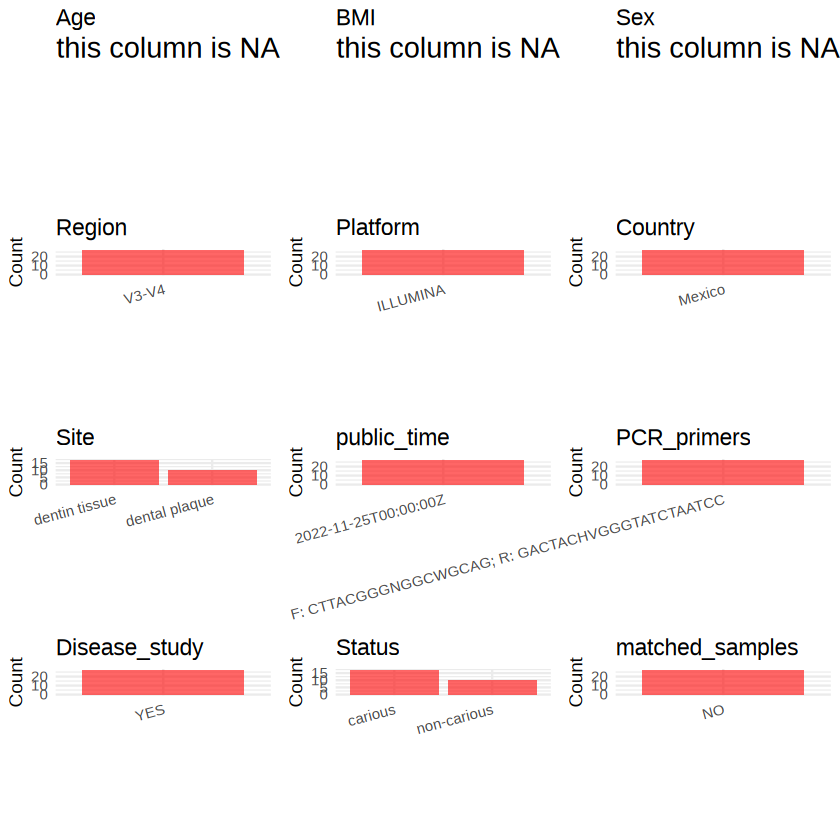

In [11]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [12]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA842423/metadata.csv", quote = T)